# 03 — Univariate visualisation

Distributions of every analysis variable, one at a time. Financial
variables are shown on linear **and** log scales — the linear panel exists
precisely to show the skew that makes the log panel necessary. Financial
plots use the complete-case sample (budget and revenue known, released by
2025); everything else uses all 9,996 cleaned films. Sample sizes are
printed on every panel and written to `report/stats/ch03_univariate.json`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.load import load_interim
from src.plotting import apply_style, save_fig
from src.reporting import write_stats

apply_style()
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

stats = {}

df = load_interim("movies_clean")
fin = df[df["has_financials"] & ~df["is_future"]].copy()
stats["n_all"] = len(df)
stats["n_financial"] = len(fin)
print(f"all films: {len(df):,}   financial sample: {len(fin):,}")

all films: 9,996   financial sample: 6,560


## Budget and revenue — linear and log

The linear panels are deliberately kept: they show that both variables
span four orders of magnitude and pile up against zero, which is why every
later financial plot uses a log scale.

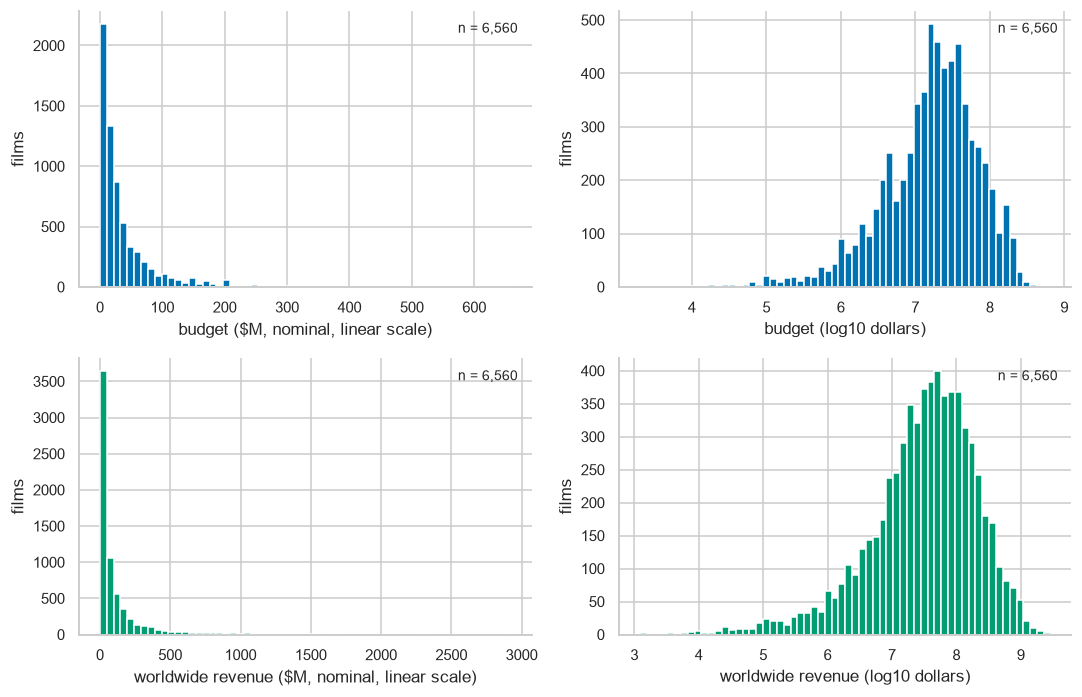

skewness: budget 2.98, revenue 4.84 (log panels are near-symmetric)


In [2]:
budget = fin["Budget"].astype("float64")
revenue = fin["Worldwide_Revenue"].astype("float64")
stats["budget_skew"] = round(float(budget.skew()), 2)
stats["revenue_skew"] = round(float(revenue.skew()), 2)
stats["budget_median"] = float(budget.median())
stats["revenue_median"] = float(revenue.median())

fig, axes = plt.subplots(2, 2, figsize=(10, 6.5))
axes[0, 0].hist(budget / 1e6, bins=60, color="C0")
axes[0, 0].set_xlabel("budget ($M, nominal, linear scale)")
axes[0, 0].set_ylabel("films")
axes[0, 1].hist(np.log10(budget), bins=60, color="C0")
axes[0, 1].set_xlabel("budget (log10 dollars)")
axes[0, 1].set_ylabel("films")
axes[1, 0].hist(revenue / 1e6, bins=60, color="C2")
axes[1, 0].set_xlabel("worldwide revenue ($M, nominal, linear scale)")
axes[1, 0].set_ylabel("films")
axes[1, 1].hist(np.log10(revenue), bins=60, color="C2")
axes[1, 1].set_xlabel("worldwide revenue (log10 dollars)")
axes[1, 1].set_ylabel("films")
for ax in axes.flat:
    ax.annotate(f"n = {len(fin):,}", xy=(0.97, 0.92), xycoords="axes fraction", ha="right", fontsize=9)
fig.tight_layout()
save_fig(fig, "fig3_1_budget_revenue_dist")
plt.show()
print(f"skewness: budget {stats['budget_skew']}, revenue {stats['revenue_skew']} (log panels are near-symmetric)")

## Runtime, audience rating, release year

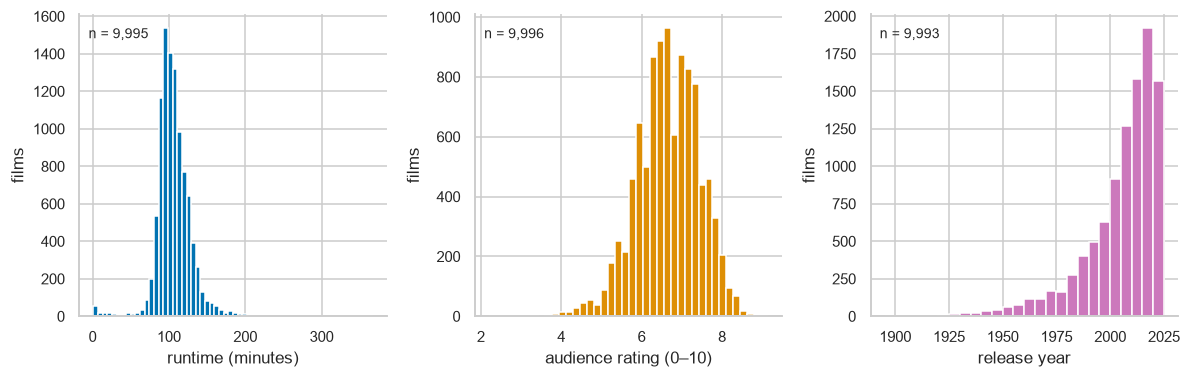

In [3]:
runtime = df["Runtime_Mins"].dropna().astype("float64")
rating = df["Audience_Rating"].dropna().astype("float64")
years = df["Release_Year"].dropna().astype("float64")
stats["runtime_skew"] = round(float(runtime.skew()), 2)
stats["rating_skew"] = round(float(rating.skew()), 2)
stats["rating_mean"] = round(float(rating.mean()), 2)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
axes[0].hist(runtime, bins=60, color="C0")
axes[0].set_xlabel("runtime (minutes)")
axes[0].set_ylabel("films")
axes[1].hist(rating, bins=40, color="C1")
axes[1].set_xlabel("audience rating (0–10)")
axes[1].set_ylabel("films")
axes[2].hist(years, bins=np.arange(1895, 2030, 5), color="C4")
axes[2].set_xlabel("release year")
axes[2].set_ylabel("films")
for ax, n in zip(axes, [len(runtime), len(rating), len(years)]):
    ax.annotate(f"n = {n:,}", xy=(0.03, 0.92), xycoords="axes fraction", fontsize=9)
fig.tight_layout()
save_fig(fig, "fig3_2_runtime_rating_year_dist")
plt.show()

Runtime is mildly right-skewed around a ~104-minute median, with a long
documentary/epic tail. Ratings are near-symmetric around the mid-6s — the
vote filter (min 367 votes) has already removed the worst-rated obscure
films. The year histogram shows the collection is heavily weighted to
post-1990 cinema; whatever we conclude is mostly about the modern industry.

## Films per year, with and without known financials

Shows both the growth of the collection and where the financial
complete-case sample actually comes from.

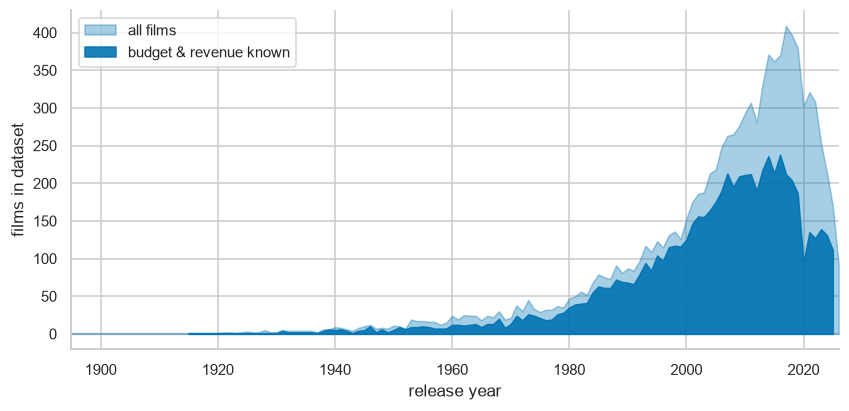

In [4]:
per_year = df.groupby(df["Release_Year"].astype("float64"))["Title"].count()
per_year_fin = fin.groupby(fin["Release_Year"].astype("float64"))["Title"].count()

fig, ax = plt.subplots(figsize=(9, 4))
ax.fill_between(per_year.index, per_year.values, color="C0", alpha=0.35, label="all films")
ax.fill_between(per_year_fin.index, per_year_fin.values, color="C0", alpha=0.9, label="budget & revenue known")
ax.set_xlabel("release year")
ax.set_ylabel("films in dataset")
ax.set_xlim(1895, 2026)
ax.legend()
save_fig(fig, "fig3_3_films_per_year")
stats["pct_films_since_1990"] = round(float((df["Release_Year"] >= 1990).mean()) * 100, 1)
stats["pct_fin_since_1990"] = round(float((fin["Release_Year"] >= 1990).mean()) * 100, 1)
plt.show()

## Genre and language frequency

Genres are multi-label, so films are **exploded**: a film tagged
"Action, Adventure" counts once under each genre, and the bars sum to more
than the number of films. The label order in the raw string is ignored.

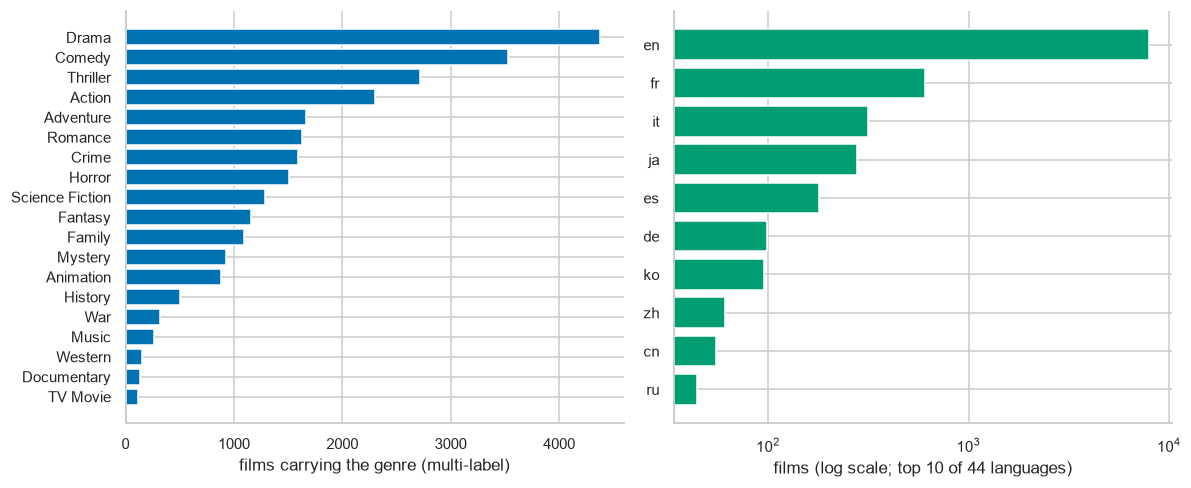

In [5]:
genres = (
    df["Genres"].dropna().str.split(",").explode().str.strip().value_counts()
)
stats["n_genres"] = len(genres)
stats["top_genre"] = genres.index[0]
stats["top_genre_count"] = int(genres.iloc[0])

lang = df["Original_Language"].value_counts()
top_lang = lang.head(10)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
axes[0].barh(genres.index[::-1], genres.values[::-1], color="C0")
axes[0].set_xlabel("films carrying the genre (multi-label)")
axes[1].barh(top_lang.index[::-1], top_lang.values[::-1], color="C2")
axes[1].set_xlabel("films (top 10 of "f"{len(lang)} languages)")
axes[1].set_xscale("log")
axes[1].set_xlabel(f"films (log scale; top 10 of {len(lang)} languages)")
fig.tight_layout()
save_fig(fig, "fig3_4_genre_language_freq")
stats["second_language"] = str(lang.index[1])
stats["second_language_count"] = int(lang.iloc[1])
stats["english_to_second_ratio"] = round(float(lang.iloc[0] / lang.iloc[1]), 1)
stats["n_genre_combinations_raw"] = int(df["Genres"].nunique())
plt.show()

Drama dominates, as it does in every large film collection; the language
panel needs a log scale because English outnumbers the second language
(French) by more than ten to one (exact ratio in the stats JSON) — a
visual reminder of how Anglophone this sample is.

## Content rating

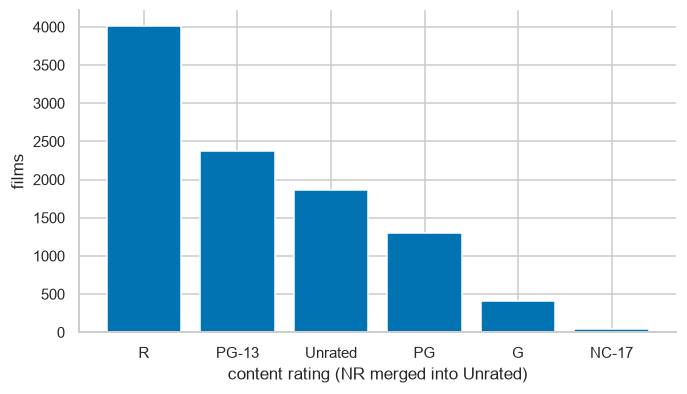

Content_Rating
R          4015
PG-13      2370
Unrated    1857
PG         1301
G           405
NC-17        48
Name: count, dtype: int64

In [6]:
cr = df["Content_Rating"].value_counts(dropna=False)
fig, ax = plt.subplots(figsize=(7, 3.8))
labels = [str(x) for x in cr.index]
ax.bar(labels, cr.values, color="C0")
ax.set_xlabel("content rating (NR merged into Unrated)")
ax.set_ylabel("films")
save_fig(fig, "fig3_5_content_rating")
plt.show()
stats["top_content_rating"] = str(cr.index[0])
stats["top_content_rating_count"] = int(cr.iloc[0])
stats["runtime_median"] = float(runtime.median())
cr

In [7]:
out = write_stats("ch03_univariate", stats)
print(f"{len(stats)} statistics written to {out.relative_to(ROOT)}")
stats

21 statistics written to report\stats\ch03_univariate.json


{'n_all': 9996,
 'n_financial': 6560,
 'budget_skew': 2.98,
 'revenue_skew': 4.84,
 'budget_median': 20000000.0,
 'revenue_median': 39197782.5,
 'runtime_skew': 0.25,
 'rating_skew': -0.33,
 'rating_mean': 6.66,
 'pct_films_since_1990': 84.8,
 'pct_fin_since_1990': 84.3,
 'n_genres': 19,
 'top_genre': 'Drama',
 'top_genre_count': 4376,
 'second_language': 'fr',
 'second_language_count': 608,
 'english_to_second_ratio': 13.1,
 'n_genre_combinations_raw': 2101,
 'top_content_rating': 'R',
 'top_content_rating_count': 4015,
 'runtime_median': 104.0}